In [1]:
# 1. Import Libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')

In [3]:
!git clone https://github.com/huzaifa-ai-ml/movie-recommendation-system.git

Cloning into 'movie-recommendation-system'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 28 (delta 8), reused 14 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 22.46 MiB | 16.66 MiB/s, done.
Resolving deltas: 100% (8/8), done.


In [4]:
import os

os.chdir('/content/movie-recommendation-system')

print("Current directory:", os.getcwd())
print("Dataset files:", os.listdir('dataset'))

Current directory: /content/movie-recommendation-system
Dataset files: ['movies.csv', 'processed_movies.csv']


In [5]:
# 2. Load Processed Dataset

ROOT_DIR = Path.cwd()

if ROOT_DIR.name == 'notebooks':
    ROOT_DIR = ROOT_DIR.parent

DATASET_DIR = ROOT_DIR / 'dataset'

df = pd.read_csv(DATASET_DIR / 'processed_movies.csv')


In [6]:
# 3. Basic Dataset Overview

print("Dataset Shape:", df.shape)
print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
display(df.isnull().sum())

Dataset Shape: (45447, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45447 entries, 0 to 45446
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   title         45447 non-null  object 
 1   overview      44493 non-null  object 
 2   genres        43005 non-null  object 
 3   tagline       20408 non-null  object 
 4   vote_average  45447 non-null  float64
 5   popularity    45447 non-null  float64
 6   tags          45187 non-null  object 
dtypes: float64(2), object(5)
memory usage: 2.4+ MB

Statistical Summary:


,vote_average,popularity
count,45447.000000,45447.000000
mean,5.618199,2.921534
std,1.924198,6.006039
min,0.000000,0.000000
25%,5.000000,0.385945
50%,6.000000,1.127513
75%,6.800000,3.679023
max,10.000000,547.488298



Missing Values:


,0
title,0
overview,954
genres,2442
tagline,25039
vote_average,0
popularity,0
tags,260


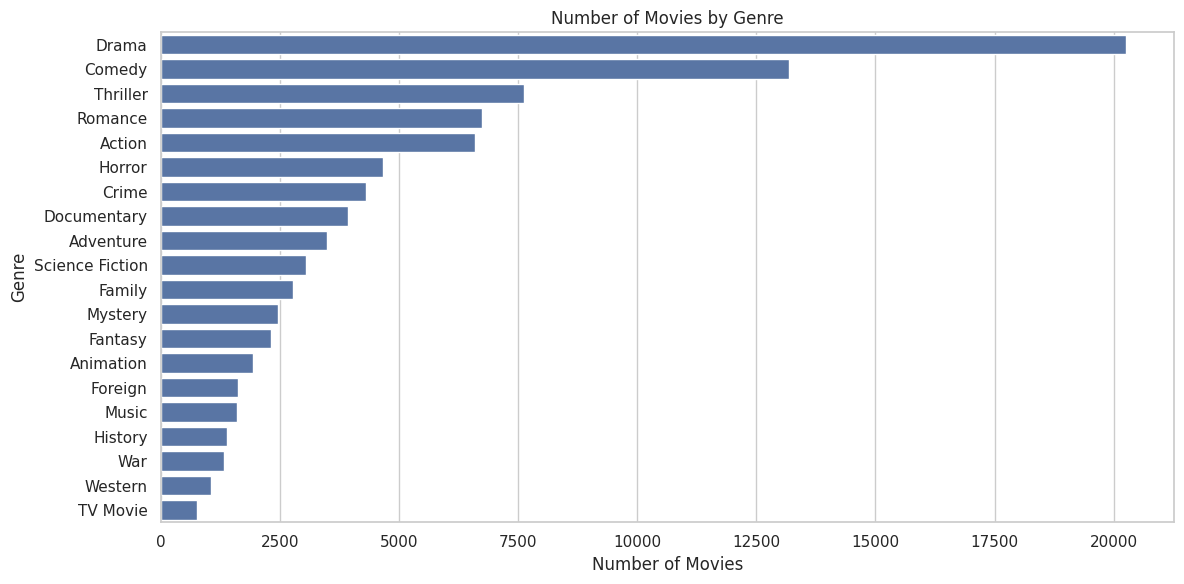

In [7]:
# 4. Movie Distribution by Genre

genre_counts = (
    df['genres']
    .dropna()
    .str.split(', ')
    .explode()
    .value_counts()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title('Number of Movies by Genre')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

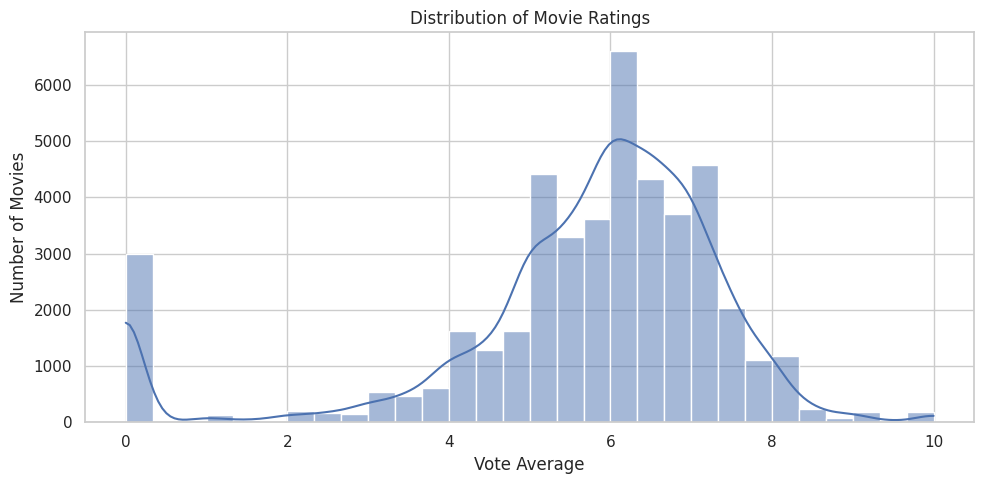

In [8]:
# 5. Vote Average Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df['vote_average'].dropna(),
    bins=30,
    kde=True
)

plt.title('Distribution of Movie Ratings')
plt.xlabel('Vote Average')
plt.ylabel('Number of Movies')
plt.tight_layout()
plt.show()

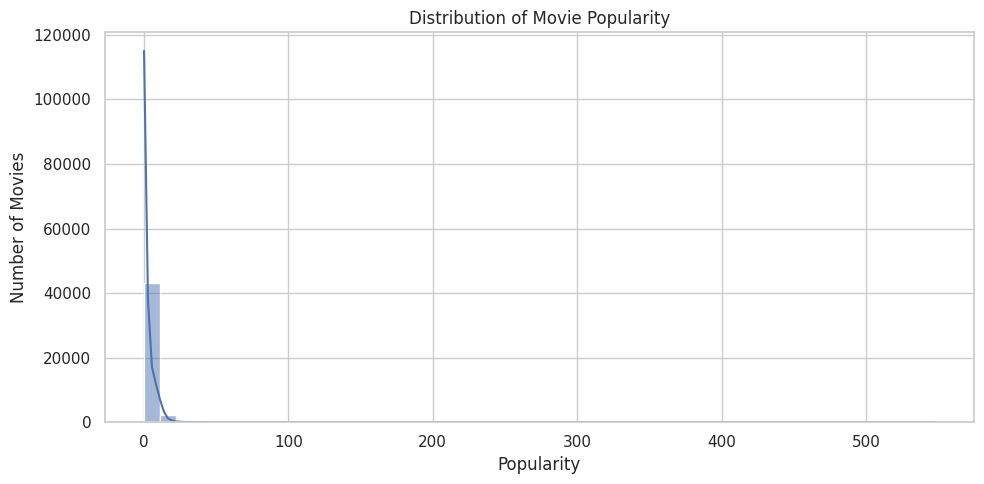

In [9]:
# 6. Popularity Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df['popularity'].dropna(),
    bins=50,
    kde=True
)

plt.title('Distribution of Movie Popularity')
plt.xlabel('Popularity')
plt.ylabel('Number of Movies')
plt.tight_layout()
plt.show()


In [10]:
# 7. Top 10 Highest-Rated Movies

top_rated = df.nlargest(10, 'vote_average')[
    ['title', 'vote_average']
]

display(top_rated)


,title,vote_average
186,Reckless,10.0
394,Girl in the Cadillac,10.0
706,"The Haunted World of Edward D. Wood, Jr.",10.0
738,Carmen Miranda: Bananas Is My Business,10.0
1633,Other Voices Other Rooms,10.0
1760,"Dancer, Texas Pop. 81",10.0
2113,The Farmer's Wife,10.0
2652,Stiff Upper Lips,10.0
2947,Ten Benny,10.0
3159,Gendernauts: A Journey Through Shifting Identi...,10.0


In [11]:
# 8. Top 10 Most Popular Movies

top_popular = df.nlargest(10, 'popularity')[
    ['title', 'popularity']
]

display(top_popular)



,title,popularity
30684,Minions,547.488298
33340,Wonder Woman,294.337037
42203,Beauty and the Beast,287.253654
43625,Baby Driver,228.032744
24444,Big Hero 6,213.849907
26552,Deadpool,187.860492
26554,Guardians of the Galaxy Vol. 2,185.330992
14547,Avatar,185.070892
24340,John Wick,183.870374
23664,Gone Girl,154.801009


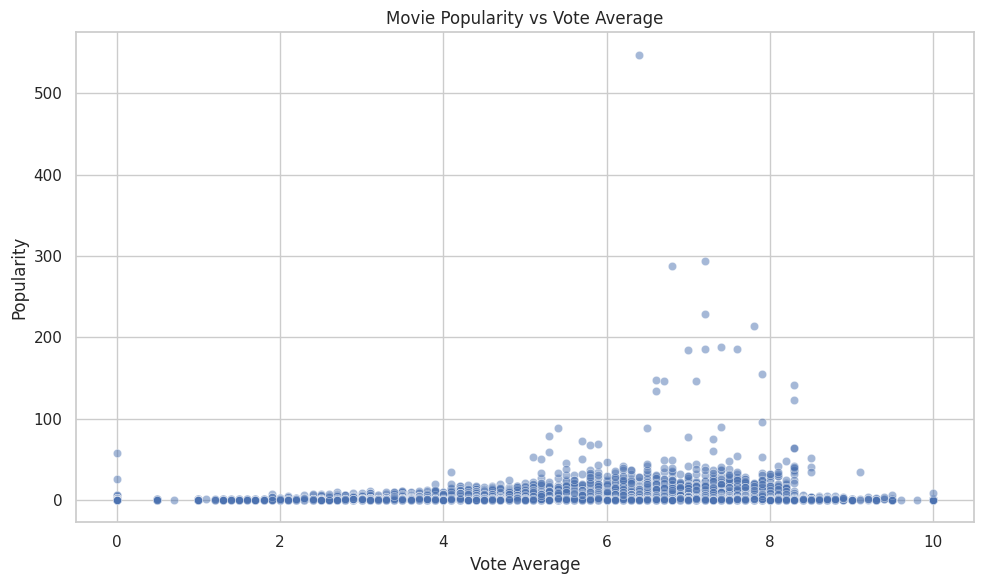

In [12]:
# 9. Popularity vs Vote Average

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='vote_average',
    y='popularity',
    alpha=0.5
)

plt.title('Movie Popularity vs Vote Average')
plt.xlabel('Vote Average')
plt.ylabel('Popularity')
plt.tight_layout()
plt.show()


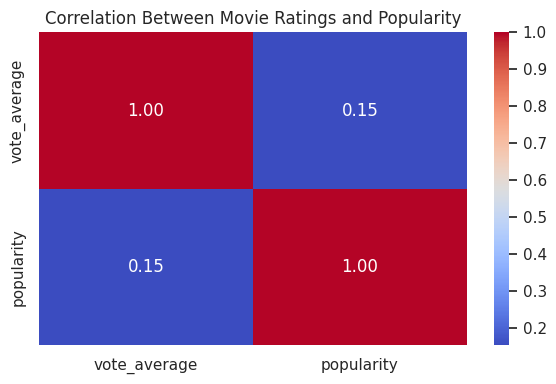

In [13]:
# 10. Correlation Analysis

correlation = df[
    ['vote_average', 'popularity']
].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Movie Ratings and Popularity')
plt.tight_layout()
plt.show()